# 高雄市本土登革熱與氣象因子描述性分析（2014–2025）
## 1. 原始資料讀取與編碼設定
讀取衛福部疾管署（NIDSS）本土登革熱月病例資料與中央氣象署（CODiS）高雄站逐月氣象年報表，並自動辨識中文編碼。

In [1]:
import os
import pandas as pd

# 1. 確認所有已上傳的 CSV 檔案清單
csv_files = sorted([f for f in os.listdir() if f.endswith('.csv')])
print("已上傳的 CSV 檔案清單：")
for f in csv_files:
    print(" -", f)

# 自動嘗試常見中文編碼讀取
def read_tw_csv(filename):
    for enc in ['utf-8-sig', 'cp950', 'big5']:
        try:
            return pd.read_csv(filename, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"無法辨識 {filename} 的編碼")

# 2. 讀取登革熱檔案（抓 20141 開頭的檔）
dengue_file = [f for f in csv_files if f.startswith('20141')][0]
df_dengue = read_tw_csv(dengue_file)
print(f"\n=== 登革熱資料 ({dengue_file}) ===")
print("欄位名稱：", df_dengue.columns.tolist())
display(df_dengue.head())

# 3. 讀取氣象檔案（各挑一份舊站 467440 與新站 467441 檢查格式是否一致）
w_old_file = [f for f in csv_files if f.startswith('467440')][0]
df_w_old = read_tw_csv(w_old_file)
print(f"\n=== 舊站氣象資料 ({w_old_file}) ===")
print("欄位名稱：", df_w_old.columns.tolist())
display(df_w_old.head(3))

w_new_file = [f for f in csv_files if f.startswith('467441')][0]
df_w_new = read_tw_csv(w_new_file)
print(f"\n=== 新站氣象資料 ({w_new_file}) ===")
print("欄位名稱：", df_w_new.columns.tolist())
display(df_w_new.head(3))

已上傳的 CSV 檔案清單：
 - 20141-202512-20140101-20.csv
 - 467440-2014.csv
 - 467440-2015.csv
 - 467440-2016.csv
 - 467440-2017.csv
 - 467440-2018.csv
 - 467440-2019.csv
 - 467440-2020.csv
 - 467440-2021.csv
 - 467440-2022.csv
 - 467441-2022.csv
 - 467441-2023.csv
 - 467441-2024.csv
 - 467441-2025.csv

=== 登革熱資料 (20141-202512-20140101-20.csv) ===
欄位名稱： ['發病年月', '已排除病例數', '檢驗中病例數', '確定病例數']


,發病年月,已排除病例數,檢驗中病例數,確定病例數
0,201401,41,0,1
1,201402,26,0,0
2,201403,37,0,0
3,201404,43,0,0
4,201405,72,0,12



=== 舊站氣象資料 (467440-2014.csv) ===
欄位名稱： ['觀測時間(month)', '測站氣壓(hPa)', '海平面氣壓(hPa)', '測站最高氣壓(hPa)', '測站最高氣壓時間(LST)', '測站最低氣壓(hPa)', '測站最低氣壓時間(LST)', '氣溫(℃)', '最高氣溫(℃)', '最高氣溫時間(LST)', '最低氣溫(℃)', '最低氣溫時間(LST)', '露點溫度(℃)', '風速(m/s)', '風向(360degree)', '最大瞬間風(m/s)', '最大瞬間風風向(360degree)', '最大瞬間風風速時間(LST)', '降水量(mm)', '降水時數(hour)', '降水日數(day)', '最大十分鐘降水量(mm)', '最大十分鐘降水量起始時間(LST)', '最大六十分鐘降水量(mm)', '最大六十分鐘降水量起始時間(LST)', '最大日降水量(mm)', '最大日降水量時間(LST)', '相對溼度(%)', 'A型蒸發量(mm)', '日照時數(hour)', '全天空日射量(MJ/㎡)', '平均日最高紫外線指數', '月最高紫外線指數', '月最高紫外線指數時間(LST)', '總雲量(0~10)', '地溫0cm', '地溫5cm', '地溫10cm', '地溫20cm', '地溫30cm']


,觀測時間(month),測站氣壓(hPa),海平面氣壓(hPa),測站最高氣壓(hPa),測站最高氣壓時間(LST),測站最低氣壓(hPa),測站最低氣壓時間(LST),氣溫(℃),最高氣溫(℃),最高氣溫時間(LST),...,全天空日射量(MJ/㎡),平均日最高紫外線指數,月最高紫外線指數,月最高紫外線指數時間(LST),總雲量(0~10),地溫0cm,地溫5cm,地溫10cm,地溫20cm,地溫30cm
0,ObsTime,StnPres,SeaPres,StnPresMax,StnPresMaxTime,StnPresMin,StnPresMinTime,Temperature,T Max,T Max Time,...,GloblRad,UVI Max Mean,UVI Max,UVI Max Time,Cloud Amount,TxSoil0cm,TxSoil5cm,TxSoil10cm,TxSoil20cm,TxSoil30cm
1,01,1019.0,1019.4,1025.5,2014/01/18 21:55:00,1010.9,2014/01/03 15:14:00,19.5,28.3,2014/01/03 13:24:00,...,449.63,4,5,2014/01/25 13:00:00,1.9,18.7,19.3,22.0,20.7,21.8
2,02,1015.8,1016.2,1025.7,2014/02/21 08:56:00,1007.0,2014/02/07 16:57:00,20.3,28.5,2014/02/06 13:03:00,...,376.83,5,7,2014/02/18 13:00:00,4.2,20.2,20.7,23.3,21.9,22.7



=== 新站氣象資料 (467441-2022.csv) ===
欄位名稱： ['觀測時間(month)', '測站氣壓(hPa)', '海平面氣壓(hPa)', '測站最高氣壓(hPa)', '測站最高氣壓時間(LST)', '測站最低氣壓(hPa)', '測站最低氣壓時間(LST)', '氣溫(℃)', '最高氣溫(℃)', '最高氣溫時間(LST)', '最低氣溫(℃)', '最低氣溫時間(LST)', '露點溫度(℃)', '風速(m/s)', '風向(360degree)', '最大瞬間風(m/s)', '最大瞬間風風向(360degree)', '最大瞬間風風速時間(LST)', '降水量(mm)', '降水時數(hour)', '降水日數(day)', '最大十分鐘降水量(mm)', '最大十分鐘降水量起始時間(LST)', '最大六十分鐘降水量(mm)', '最大六十分鐘降水量起始時間(LST)', '最大日降水量(mm)', '最大日降水量時間(LST)', '相對溼度(%)', 'A型蒸發量(mm)', '日照時數(hour)', '全天空日射量(MJ/㎡)', '平均日最高紫外線指數', '月最高紫外線指數', '月最高紫外線指數時間(LST)', '總雲量(0~10)', '地溫0cm', '地溫5cm', '地溫10cm', '地溫20cm', '地溫30cm', '地溫50cm', '地溫100cm']


,觀測時間(month),測站氣壓(hPa),海平面氣壓(hPa),測站最高氣壓(hPa),測站最高氣壓時間(LST),測站最低氣壓(hPa),測站最低氣壓時間(LST),氣溫(℃),最高氣溫(℃),最高氣溫時間(LST),...,月最高紫外線指數,月最高紫外線指數時間(LST),總雲量(0~10),地溫0cm,地溫5cm,地溫10cm,地溫20cm,地溫30cm,地溫50cm,地溫100cm
0,ObsTime,StnPres,SeaPres,StnPresMax,StnPresMaxTime,StnPresMin,StnPresMinTime,Temperature,T Max,T Max Time,...,UVI Max,UVI Max Time,Cloud Amount,TxSoil0cm,TxSoil5cm,TxSoil10cm,TxSoil20cm,TxSoil30cm,TxSoil50cm,TxSoil100cm
1,01,1013.7,1015.5,1018.3,2022/01/31 08:55:00,1007.9,2022/01/29 16:01:00,19.1,27.0,2022/01/25 13:20:00,...,10,2022/01/31 12:00:00,5.6,19.9,20.7,20.9,21.4,22.1,23.0,24.6
2,02,1016.0,1017.9,1023.1,2022/02/25 09:25:00,1008.8,2022/02/13 15:38:00,18.0,29.0,2022/02/28 13:54:00,...,14,2022/02/28 13:00:00,5.6,17.0,19.5,19.7,20.2,20.8,20.3,24.0


## 2. 欄位探索與新舊測站交接比對
檢視 2014–2021 年舊站（467440）與 2022–2025 年新站（467441）之欄位結構，確認 2022 年起改採新站完整觀測紀錄，並確認降水量欄位名稱為「降水量(mm)」。

In [2]:
print("1. 全部檔案：", csv_files)
print("2. 舊站完整欄位：", df_w_old.columns.tolist())
print("3. 新站完整欄位：", df_w_new.columns.tolist())

print("\n4. 2022 舊站前 3 列：")
print(read_tw_csv("467440-2022.csv").iloc[:3, :10])
print("\n5. 2022 新站前 3 列：")
print(read_tw_csv("467441-2022.csv").iloc[:3, :10])

1. 全部檔案： ['20141-202512-20140101-20.csv', '467440-2014.csv', '467440-2015.csv', '467440-2016.csv', '467440-2017.csv', '467440-2018.csv', '467440-2019.csv', '467440-2020.csv', '467440-2021.csv', '467440-2022.csv', '467441-2022.csv', '467441-2023.csv', '467441-2024.csv', '467441-2025.csv']
2. 舊站完整欄位： ['觀測時間(month)', '測站氣壓(hPa)', '海平面氣壓(hPa)', '測站最高氣壓(hPa)', '測站最高氣壓時間(LST)', '測站最低氣壓(hPa)', '測站最低氣壓時間(LST)', '氣溫(℃)', '最高氣溫(℃)', '最高氣溫時間(LST)', '最低氣溫(℃)', '最低氣溫時間(LST)', '露點溫度(℃)', '風速(m/s)', '風向(360degree)', '最大瞬間風(m/s)', '最大瞬間風風向(360degree)', '最大瞬間風風速時間(LST)', '降水量(mm)', '降水時數(hour)', '降水日數(day)', '最大十分鐘降水量(mm)', '最大十分鐘降水量起始時間(LST)', '最大六十分鐘降水量(mm)', '最大六十分鐘降水量起始時間(LST)', '最大日降水量(mm)', '最大日降水量時間(LST)', '相對溼度(%)', 'A型蒸發量(mm)', '日照時數(hour)', '全天空日射量(MJ/㎡)', '平均日最高紫外線指數', '月最高紫外線指數', '月最高紫外線指數時間(LST)', '總雲量(0~10)', '地溫0cm', '地溫5cm', '地溫10cm', '地溫20cm', '地溫30cm']
3. 新站完整欄位： ['觀測時間(month)', '測站氣壓(hPa)', '海平面氣壓(hPa)', '測站最高氣壓(hPa)', '測站最高氣壓時間(LST)', '測站最低氣壓(hPa)', '測站最低氣壓時間(LST)', '氣溫(℃)', '最高氣溫(℃

In [3]:
print("舊站含'雨'欄位：", [c for c in df_w_old.columns if '雨' in c])
print("新站含'雨'欄位：", [c for c in df_w_new.columns if '雨' in c])
print("所有檔案數量：", len(csv_files), csv_files)

舊站含'雨'欄位： []
新站含'雨'欄位： []
所有檔案數量： 14 ['20141-202512-20140101-20.csv', '467440-2014.csv', '467440-2015.csv', '467440-2016.csv', '467440-2017.csv', '467440-2018.csv', '467440-2019.csv', '467440-2020.csv', '467440-2021.csv', '467440-2022.csv', '467441-2022.csv', '467441-2023.csv', '467441-2024.csv', '467441-2025.csv']


In [4]:
print("=== 舊站 467440 全部欄位 ===")
for i, c in enumerate(df_w_old.columns):
    print(f"{i}: {c}")

print("\n=== 新站 467441 全部欄位 ===")
for i, c in enumerate(df_w_new.columns):
    print(f"{i}: {c}")

=== 舊站 467440 全部欄位 ===
0: 觀測時間(month)
1: 測站氣壓(hPa)
2: 海平面氣壓(hPa)
3: 測站最高氣壓(hPa)
4: 測站最高氣壓時間(LST)
5: 測站最低氣壓(hPa)
6: 測站最低氣壓時間(LST)
7: 氣溫(℃)
8: 最高氣溫(℃)
9: 最高氣溫時間(LST)
10: 最低氣溫(℃)
11: 最低氣溫時間(LST)
12: 露點溫度(℃)
13: 風速(m/s)
14: 風向(360degree)
15: 最大瞬間風(m/s)
16: 最大瞬間風風向(360degree)
17: 最大瞬間風風速時間(LST)
18: 降水量(mm)
19: 降水時數(hour)
20: 降水日數(day)
21: 最大十分鐘降水量(mm)
22: 最大十分鐘降水量起始時間(LST)
23: 最大六十分鐘降水量(mm)
24: 最大六十分鐘降水量起始時間(LST)
25: 最大日降水量(mm)
26: 最大日降水量時間(LST)
27: 相對溼度(%)
28: A型蒸發量(mm)
29: 日照時數(hour)
30: 全天空日射量(MJ/㎡)
31: 平均日最高紫外線指數
32: 月最高紫外線指數
33: 月最高紫外線指數時間(LST)
34: 總雲量(0~10)
35: 地溫0cm
36: 地溫5cm
37: 地溫10cm
38: 地溫20cm
39: 地溫30cm

=== 新站 467441 全部欄位 ===
0: 觀測時間(month)
1: 測站氣壓(hPa)
2: 海平面氣壓(hPa)
3: 測站最高氣壓(hPa)
4: 測站最高氣壓時間(LST)
5: 測站最低氣壓(hPa)
6: 測站最低氣壓時間(LST)
7: 氣溫(℃)
8: 最高氣溫(℃)
9: 最高氣溫時間(LST)
10: 最低氣溫(℃)
11: 最低氣溫時間(LST)
12: 露點溫度(℃)
13: 風速(m/s)
14: 風向(360degree)
15: 最大瞬間風(m/s)
16: 最大瞬間風風向(360degree)
17: 最大瞬間風風速時間(LST)
18: 降水量(mm)
19: 降水時數(hour)
20: 降水日數(day)
21: 最大十分鐘降水量(mm)
22: 最大十分鐘降水量起始時間(LST)
23: 最大六十分鐘

## 3. 資料清理、微量降雨處理與 144 個月時間序列合併
建立 2014/01–2025/12 完整 144 個月骨架並將無病例月份補 0，同時將氣象資料中之微量降雨記號 `T` 轉為 `0.05` mm 後完成合併。

In [5]:
import pandas as pd
import numpy as np

# ==========================================
# 1. 清理登革熱資料（2014–2025 高雄本土病例）
# ==========================================
# 只保留需要的兩欄，並重新命名方便後續操作
dengue_clean = df_dengue[['發病年月', '確定病例數']].copy()
dengue_clean.columns = ['ym_raw', 'cases']

# 將 201401 拆解成整數的 year 與 month，並建立標準 'YYYY-MM' 字串
dengue_clean['ym_raw'] = dengue_clean['ym_raw'].astype(str).str.strip()
dengue_clean['year'] = dengue_clean['ym_raw'].str[:4].astype(int)
dengue_clean['month'] = dengue_clean['ym_raw'].str[4:6].astype(int)
dengue_clean['cases'] = pd.to_numeric(dengue_clean['cases'], errors='coerce').fillna(0).astype(int)

# 建立 2014年1月 到 2025年12月 完整的 144 個月時間骨架，確保無病例月份補 0
full_grid = pd.MultiIndex.from_product(
    [range(2014, 2026), range(1, 13)], names=['year', 'month']
).to_frame().reset_index(drop=True)

dengue_144 = pd.merge(full_grid, dengue_clean[['year', 'month', 'cases']], on=['year', 'month'], how='left')
dengue_144['cases'] = dengue_144['cases'].fillna(0).astype(int)

# ==========================================
# 2. 清理並串接高雄氣象資料（舊站 2014-2021 + 新站 2022-2025）
# ==========================================
weather_list = []

# 定義要讀取的 (站號, 年份) 清單：2014-2021 用舊站 467440，2022-2025 用新站 467441
station_years = [(467440, y) for y in range(2014, 2022)] + [(467441, y) for y in range(2022, 2026)]

for stn, yr in station_years:
    fname = f"{stn}-{yr}.csv"
    df_tmp = read_tw_csv(fname)

    # 第 0 列是英文代碼 (ObsTime, Temperature...)，從第 1 列開始才是月份資料
    df_tmp = df_tmp.iloc[1:].copy()

    # 取出確切欄位並重新命名
    sub = df_tmp[['觀測時間(month)', '氣溫(℃)', '降水量(mm)']].copy()
    sub.columns = ['month', 'temp_c', 'rain_mm']
    sub['year'] = yr
    sub['station'] = str(stn)

    # 檢查是否有特殊符號（例如氣象署常用 'T' 代表微量降雨 <0.1mm，或 '--' 代表無資料）
    for col in ['temp_c', 'rain_mm']:
        non_num = sub[pd.to_numeric(sub[col], errors='coerce').isna()][col].unique()
        if len(non_num) > 0:
            print(f"⚠️ {fname} 的 {col} 含有非數字記號：{non_num}")

    # 將 'T'（微量降雨）轉為 0.05，其餘轉為浮點數
    sub['rain_mm'] = sub['rain_mm'].replace('T', 0.05)
    sub['temp_c'] = pd.to_numeric(sub['temp_c'], errors='coerce')
    sub['rain_mm'] = pd.to_numeric(sub['rain_mm'], errors='coerce')
    sub['month'] = sub['month'].astype(int)

    weather_list.append(sub)

weather_144 = pd.concat(weather_list, ignore_index=True)

# ==========================================
# 3. 合併登革熱與氣象資料，並檢查資料品質
# ==========================================
df_merged = pd.merge(dengue_144, weather_144, on=['year', 'month'], how='left')
df_merged['ym'] = df_merged['year'].astype(str) + '-' + df_merged['month'].astype(str).str.zfill(2)

# 調整欄位順序方便閱讀
df_merged = df_merged[['ym', 'year', 'month', 'station', 'cases', 'temp_c', 'rain_mm']]

print("\n=== 合併完成檢查 ===")
print("總列數（預期 144 列）：", len(df_merged))
print("各欄位缺漏值數量：\n", df_merged.isna().sum())
print("\n=== 敘述統計摘要 ===")
display(df_merged[['cases', 'temp_c', 'rain_mm']].describe().round(2))
print("\n=== 前 12 列預覽（2014 全年） ===")
display(df_merged.head(12))

⚠️ 467441-2022.csv 的 rain_mm 含有非數字記號：['T']
⚠️ 467441-2023.csv 的 rain_mm 含有非數字記號：['T']
⚠️ 467441-2024.csv 的 rain_mm 含有非數字記號：['T']

=== 合併完成檢查 ===
總列數（預期 144 列）： 144
各欄位缺漏值數量：
 ym         0
year       0
month      0
station    0
cases      0
temp_c     0
rain_mm    0
dtype: int64

=== 敘述統計摘要 ===


,cases,temp_c,rain_mm
count,144.00,144.00,144.00
mean,267.06,25.56,173.45
std,1091.75,3.64,268.03
min,0.00,17.20,0.00
25%,0.00,22.55,9.38
50%,0.00,26.50,50.25
75%,6.25,28.62,227.50
max,8914.00,30.60,1600.50



=== 前 12 列預覽（2014 全年） ===


,ym,year,month,station,cases,temp_c,rain_mm
0,2014-01,2014,1,467440,1,19.5,0.0
1,2014-02,2014,2,467440,0,20.3,16.0
2,2014-03,2014,3,467440,0,22.6,67.0
3,2014-04,2014,4,467440,0,25.9,27.0
4,2014-05,2014,5,467440,12,27.8,198.5
5,2014-06,2014,6,467440,92,29.2,235.0
6,2014-07,2014,7,467440,366,30.3,309.5
7,2014-08,2014,8,467440,937,29.1,902.0
8,2014-09,2014,9,467440,2192,29.5,172.0
9,2014-10,2014,10,467440,5328,27.2,0.0


## 4. 年度差異彙總與時間差（Lag 0–4 個月）相關性檢定
計算各年度病例總數與氣象摘要（回應規格第 3 題），並比較 Pearson 與 Spearman 兩種相關係數在不同時間差下的表現，同時匯出乾淨主資料集至 `data/`。

In [6]:
import os
import pandas as pd
import numpy as np

os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# 匯出合併後的乾淨 144 個月主資料集
df_merged = df_merged.drop(columns=['log_cases'], errors='ignore')
df_merged.to_csv('data/kaohsiung_dengue_weather_2014_2025.csv', index=False, encoding='utf-8-sig')

# 1. 年度彙總表（回答規格第 3 題：年份差異）
annual_summary = df_merged.groupby('year').agg(
    total_cases=('cases', 'sum'),
    max_monthly_cases=('cases', 'max'),
    mean_temp_c=('temp_c', 'mean'),
    total_rain_mm=('rain_mm', 'sum')
).round(1)

print("=== 2014–2025 年高雄市本土登革熱與氣象年度彙總表 ===")
display(annual_summary)

# 2. 時間差相關係數表（同時呈現 Pearson 與 Spearman 至小數點後 3 位）
lags = [0, 1, 2, 3, 4]
lag_table = pd.DataFrame({
    'lag_months': lags,
    'pearson_temp': [df_merged['cases'].corr(df_merged['temp_c'].shift(k), method='pearson') for k in lags],
    'pearson_rain': [df_merged['cases'].corr(df_merged['rain_mm'].shift(k), method='pearson') for k in lags],
    'spearman_temp': [df_merged['cases'].corr(df_merged['temp_c'].shift(k), method='spearman') for k in lags],
    'spearman_rain': [df_merged['cases'].corr(df_merged['rain_mm'].shift(k), method='spearman') for k in lags],
}).round(3)

print("\n=== 氣象因子領先 0–4 個月相關係數表 ===")
display(lag_table)

=== 2014–2025 年高雄市本土登革熱與氣象年度彙總表 ===


,total_cases,max_monthly_cases,mean_temp_c,total_rain_mm
year,,,,
2014,14999,5328,25.6,1942.0
2015,19723,8914,26.1,1344.0
2016,342,331,25.9,3103.5
2017,3,3,26.3,1124.5
2018,12,8,25.9,3068.2
2019,58,22,26.3,2226.0
2020,0,0,26.4,2162.5
2021,0,0,25.4,2600.4
2022,18,16,24.6,945.6



=== 氣象因子領先 0–4 個月相關係數表 ===


,lag_months,pearson_temp,pearson_rain,spearman_temp,spearman_rain
0,0,0.042,-0.090,0.128,0.120
1,1,0.157,-0.010,0.198,0.172
2,2,0.216,0.133,0.230,0.184
3,3,0.240,0.189,0.168,0.134
4,4,0.242,0.064,0.067,-0.010


## 5. 視覺化與成果匯出
產出 4 張圖：線性與對數尺度時間序列、平均值與中位數季節輪廓、Lag 0–4 相關係數圖，存入 `figures/`。最後的打包下載僅限 Colab 環境使用。

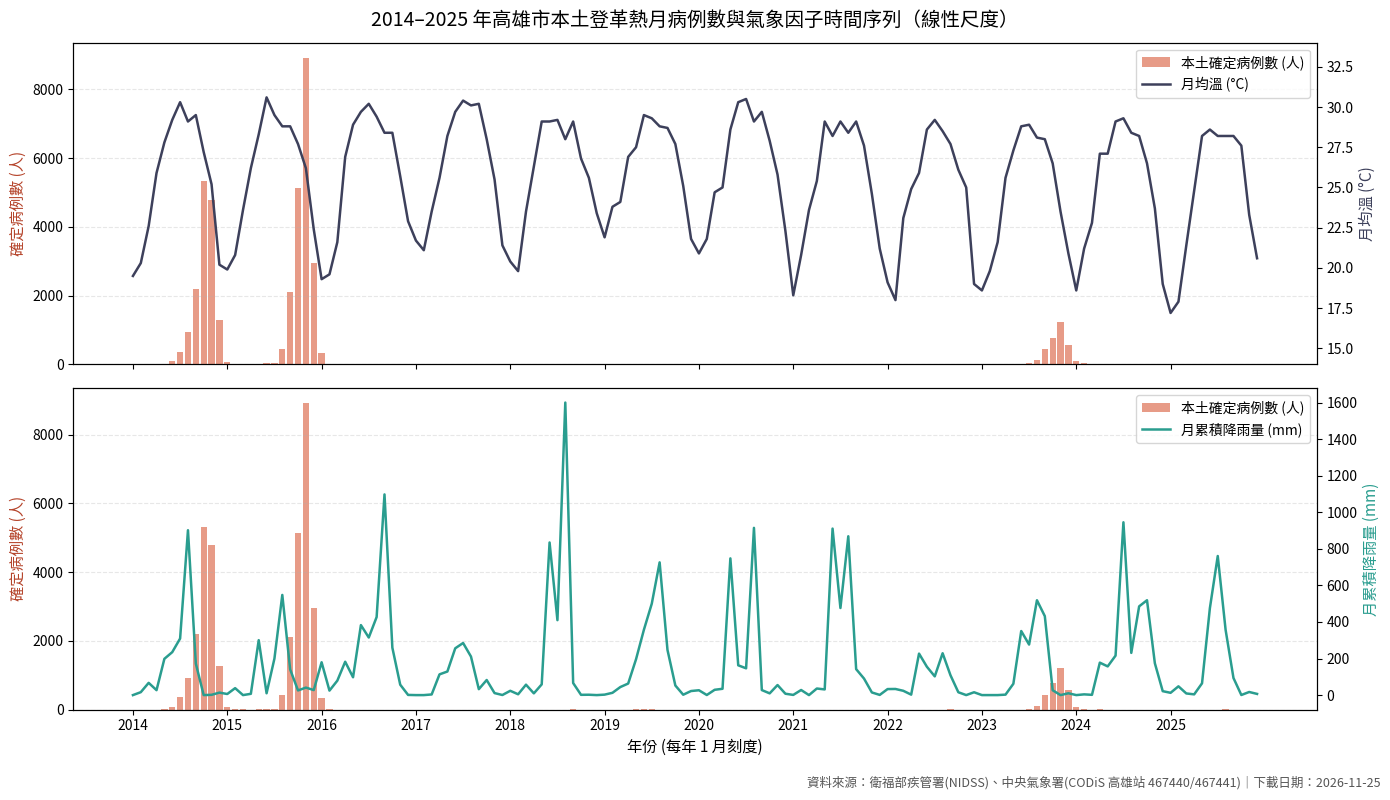

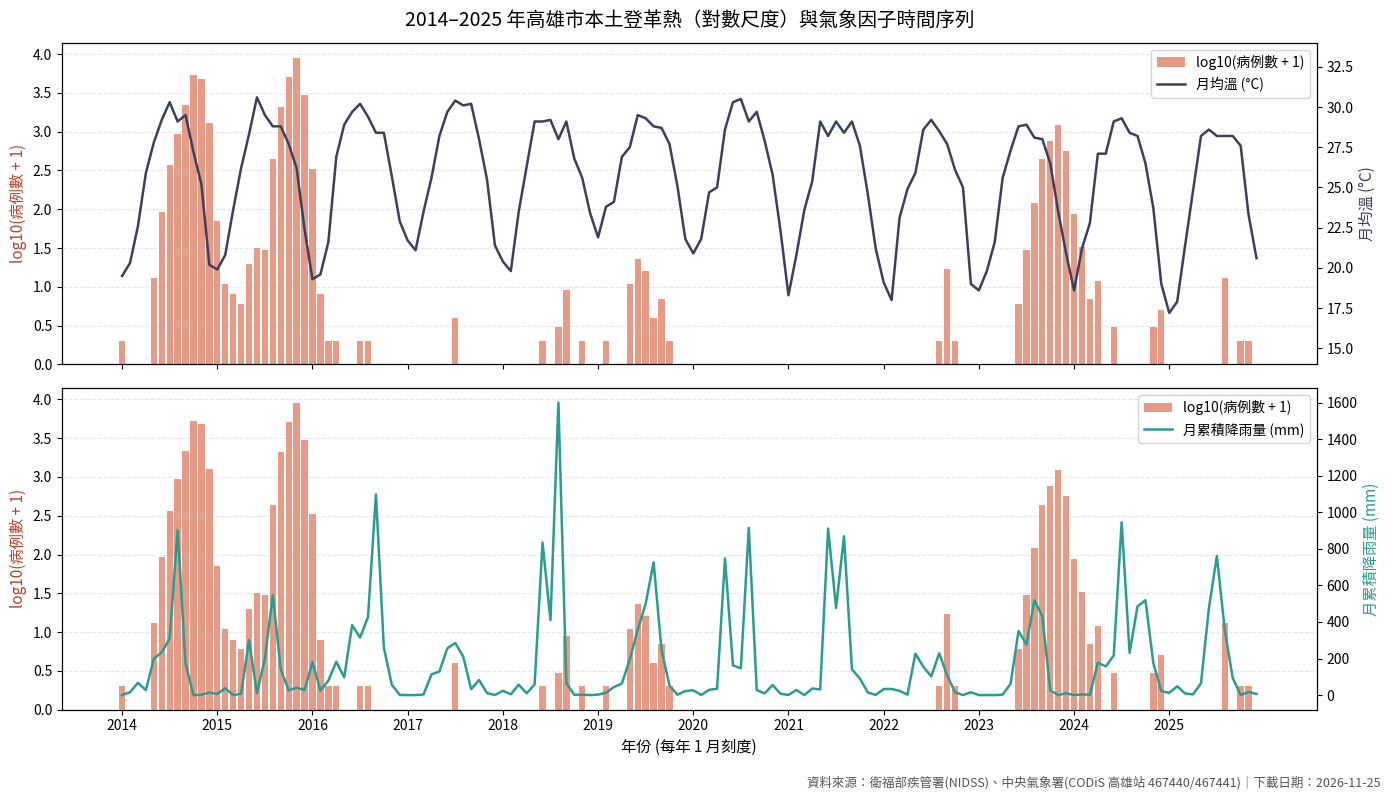

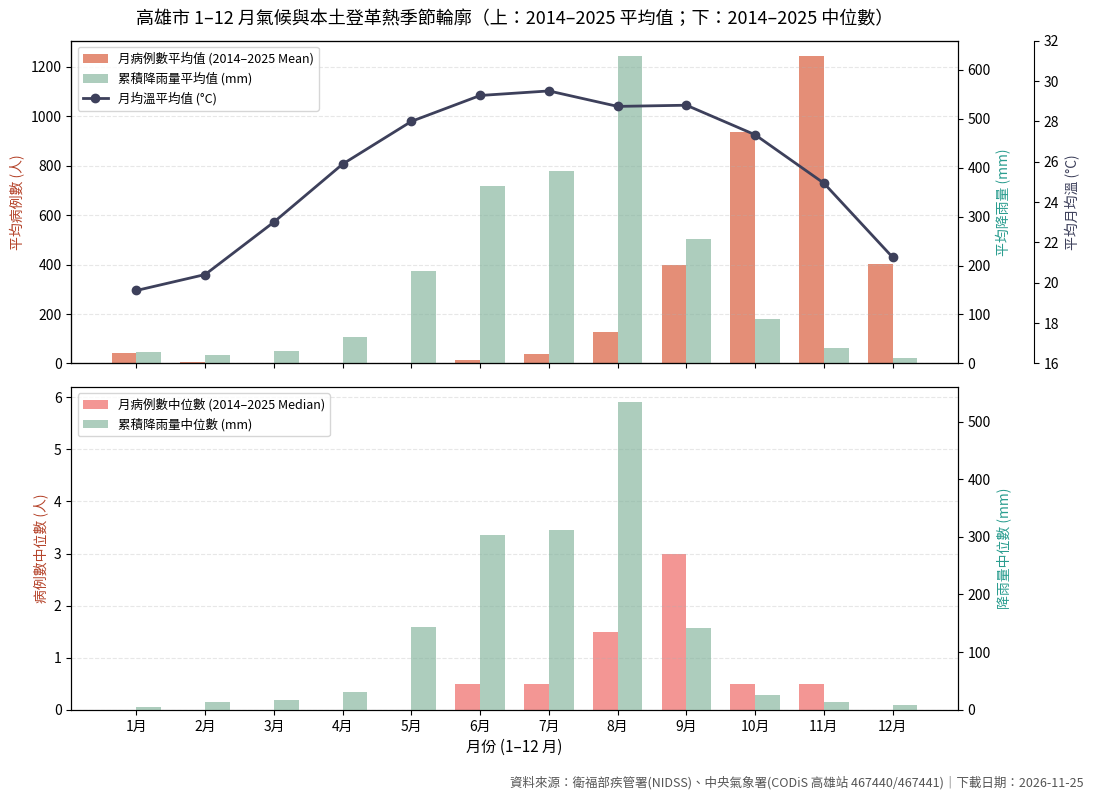

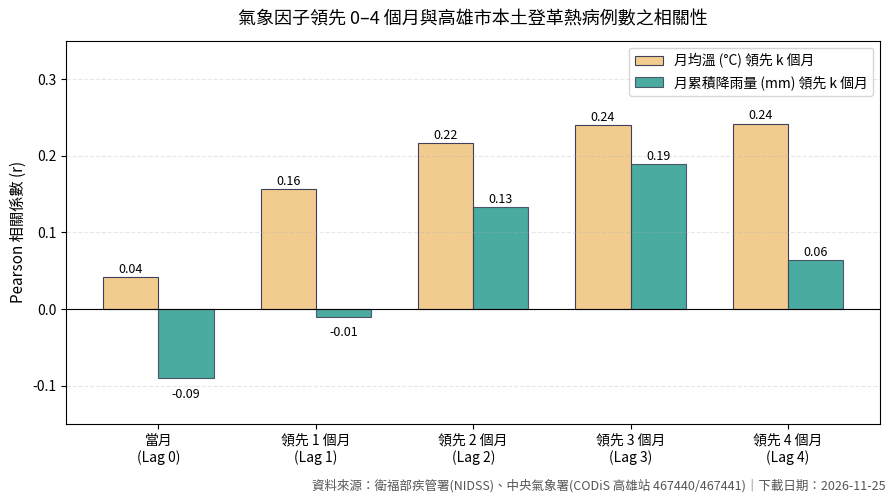

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import zipfile
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from google.colab import files

# 載入繁體中文字型
if not os.path.exists('NotoSansCJKtc-Regular.otf'):
    !wget -q -O NotoSansCJKtc-Regular.otf https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf

fm.fontManager.addfont('NotoSansCJKtc-Regular.otf')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC']
plt.rcParams['axes.unicode_minus'] = False

source_text = "資料來源：衛福部疾管署(NIDSS)、中央氣象署(CODiS 高雄站 467440/467441)｜下載日期：2026-11-25"
x = np.arange(len(df_merged))
xticks_pos = [i for i, m in enumerate(df_merged['month']) if m == 1]
xticks_lbl = [str(y) for y in df_merged.loc[xticks_pos, 'year']]

# --- 圖 1A：線性尺度雙軸時間序列 ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
b1 = ax1.bar(x, df_merged['cases'], color='#E07A5F', alpha=0.75, label='本土確定病例數 (人)')
ax1.set_ylabel('確定病例數 (人)', color='#B5442B', fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1_t = ax1.twinx()
l1 = ax1_t.plot(x, df_merged['temp_c'], color='#3D405B', linewidth=1.8, label='月均溫 (°C)')
ax1_t.set_ylabel('月均溫 (°C)', color='#3D405B', fontsize=11)
ax1_t.set_ylim(14, 34)
ax1.set_title('2014–2025 年高雄市本土登革熱月病例數與氣象因子時間序列（線性尺度）', fontsize=14, pad=12)
ax1.legend([b1] + l1, [b1.get_label(), l1[0].get_label()], loc='upper right', frameon=True)

b2 = ax2.bar(x, df_merged['cases'], color='#E07A5F', alpha=0.75, label='本土確定病例數 (人)')
ax2.set_ylabel('確定病例數 (人)', color='#B5442B', fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.3)
ax2_r = ax2.twinx()
l2 = ax2_r.plot(x, df_merged['rain_mm'], color='#2A9D8F', linewidth=1.8, label='月累積降雨量 (mm)')
ax2_r.set_ylabel('月累積降雨量 (mm)', color='#2A9D8F', fontsize=11)
ax2.set_xticks(xticks_pos)
ax2.set_xticklabels(xticks_lbl, fontsize=10)
ax2.set_xlabel('年份 (每年 1 月刻度)', fontsize=11)
ax2.legend([b2] + l2, [b2.get_label(), l2[0].get_label()], loc='upper right', frameon=True)

fig.text(0.99, 0.01, source_text, ha='right', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('figures/fig1_timeseries.png', dpi=300)
plt.show()

# --- 圖 1B：對數尺度 log10(cases + 1) 版本 ---
df_merged['log_cases'] = np.log10(df_merged['cases'] + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
b1 = ax1.bar(x, df_merged['log_cases'], color='#E07A5F', alpha=0.75, label='log10(病例數 + 1)')
ax1.set_ylabel('log10(病例數 + 1)', color='#B5442B', fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1_t = ax1.twinx()
l1 = ax1_t.plot(x, df_merged['temp_c'], color='#3D405B', linewidth=1.8, label='月均溫 (°C)')
ax1_t.set_ylabel('月均溫 (°C)', color='#3D405B', fontsize=11)
ax1_t.set_ylim(14, 34)
ax1.set_title('2014–2025 年高雄市本土登革熱（對數尺度）與氣象因子時間序列', fontsize=14, pad=12)
ax1.legend([b1] + l1, [b1.get_label(), l1[0].get_label()], loc='upper right', frameon=True)

b2 = ax2.bar(x, df_merged['log_cases'], color='#E07A5F', alpha=0.75, label='log10(病例數 + 1)')
ax2.set_ylabel('log10(病例數 + 1)', color='#B5442B', fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.3)
ax2_r = ax2.twinx()
l2 = ax2_r.plot(x, df_merged['rain_mm'], color='#2A9D8F', linewidth=1.8, label='月累積降雨量 (mm)')
ax2_r.set_ylabel('月累積降雨量 (mm)', color='#2A9D8F', fontsize=11)
ax2.set_xticks(xticks_pos)
ax2.set_xticklabels(xticks_lbl, fontsize=10)
ax2.set_xlabel('年份 (每年 1 月刻度)', fontsize=11)
ax2.legend([b2] + l2, [b2.get_label(), l2[0].get_label()], loc='upper right', frameon=True)

fig.text(0.99, 0.01, source_text, ha='right', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('figures/fig1b_timeseries_log.png', dpi=300)
plt.show()

# --- 圖 2：1–12 月季節輪廓圖（上：全期平均 Mean；下：全期中位數 Median，消除極端年主導） ---
s_mean = df_merged.groupby('month')[['cases', 'temp_c', 'rain_mm']].mean().reset_index()
s_median = df_merged.groupby('month')[['cases', 'rain_mm']].median().reset_index()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
months = s_mean['month']

# 上圖：2014–2025 全期平均值
b_mean = ax_top.bar(months - 0.18, s_mean['cases'], width=0.36, color='#E07A5F', alpha=0.85, label='月病例數平均值 (2014–2025 Mean)')
ax_top.set_ylabel('平均病例數 (人)', color='#B5442B', fontsize=10)
ax_top.grid(axis='y', linestyle='--', alpha=0.3)
ax_top_r = ax_top.twinx()
b_rain_mean = ax_top_r.bar(months + 0.18, s_mean['rain_mm'], width=0.36, color='#81B29A', alpha=0.65, label='累積降雨量平均值 (mm)')
ax_top_r.set_ylabel('平均降雨量 (mm)', color='#2A9D8F', fontsize=10)
ax_top_t = ax_top.twinx()
ax_top_t.spines['right'].set_position(('outward', 55))
l_temp = ax_top_t.plot(months, s_mean['temp_c'], color='#3D405B', marker='o', linewidth=2, label='月均溫平均值 (°C)')
ax_top_t.set_ylabel('平均月均溫 (°C)', color='#3D405B', fontsize=10)
ax_top_t.set_ylim(16, 32)
ax_top.set_title('高雄市 1–12 月氣候與本土登革熱季節輪廓（上：2014–2025 平均值；下：2014–2025 中位數）', fontsize=13, pad=12)
ax_top.legend([b_mean, b_rain_mean] + l_temp, [b_mean.get_label(), b_rain_mean.get_label(), l_temp[0].get_label()], loc='upper left', fontsize=9)

# 下圖：2014–2025 全期中位數（不受極端流行年拉高）
b_med = ax_bot.bar(months - 0.18, s_median['cases'], width=0.36, color='#F28482', alpha=0.85, label='月病例數中位數 (2014–2025 Median)')
ax_bot.set_ylabel('病例數中位數 (人)', color='#B5442B', fontsize=10)
ax_bot.set_ylim(0, max(s_median['cases']) * 1.4 + 2)
ax_bot.set_xticks(range(1, 13))
ax_bot.set_xticklabels([f'{m}月' for m in range(1, 13)])
ax_bot.set_xlabel('月份 (1–12 月)', fontsize=11)
ax_bot.grid(axis='y', linestyle='--', alpha=0.3)
ax_bot_r = ax_bot.twinx()
b_rain_med = ax_bot_r.bar(months + 0.18, s_median['rain_mm'], width=0.36, color='#81B29A', alpha=0.65, label='累積降雨量中位數 (mm)')
ax_bot_r.set_ylabel('降雨量中位數 (mm)', color='#2A9D8F', fontsize=10)
ax_bot.legend([b_med, b_rain_med], [b_med.get_label(), b_rain_med.get_label()], loc='upper left', fontsize=9)

fig.text(0.99, 0.01, source_text, ha='right', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('figures/fig2_seasonal_profile.png', dpi=300)
plt.show()

# --- 圖 3：時間差相關係數圖 ---
fig, ax = plt.subplots(figsize=(9, 5))
x_lag = np.arange(len(lags))
w = 0.35

r1 = ax.bar(x_lag - w/2, lag_table['pearson_temp'], width=w, color='#F2CC8F', edgecolor='#3D405B', linewidth=0.8, label='月均溫 (°C) 領先 k 個月')
r2 = ax.bar(x_lag + w/2, lag_table['pearson_rain'], width=w, color='#2A9D8F', edgecolor='#3D405B', linewidth=0.8, alpha=0.85, label='月累積降雨量 (mm) 領先 k 個月')

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x_lag)
ax.set_xticklabels([f'當月\n(Lag 0)' if k == 0 else f'領先 {k} 個月\n(Lag {k})' for k in lags])
ax.set_ylabel('Pearson 相關係數 (r)', fontsize=11)
ax.set_ylim(-0.15, 0.35)
ax.set_title('氣象因子領先 0–4 個月與高雄市本土登革熱病例數之相關性', fontsize=13, pad=12)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(loc='upper right', frameon=True)

for bars in [r1, r2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3 if h >= 0 else -14), textcoords='offset points',
                    ha='center', fontsize=9)

fig.text(0.99, 0.01, source_text, ha='right', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('figures/fig3_lag_correlation.png', dpi=300)
plt.show()

# --- 僅在 Google Colab 環境打包下載用 ---
with zipfile.ZipFile('dengue_kaohsiung_assets.zip', 'w') as zf:
    zf.write('data/kaohsiung_dengue_weather_2014_2025.csv')
    for fig_name in sorted(os.listdir('figures')):
        zf.write(f'figures/{fig_name}')

files.download('dengue_kaohsiung_assets.zip')